<a href="https://colab.research.google.com/github/hamptb/MANE-4961/blob/main/HW4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Construct a fully connected neural network model for classifying CIFAR-10 dataset. Use a 70%-30% split for training and validation data.

a) (10pts) Visualize the data by plotting an image from each category from the CIFAR-10 dataset.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from sklearn.model_selection import train_test_split

# Load the CIFAR-10 dataset
(x_train_full, y_train_full), (x_test, y_test) = cifar10.load_data()

# Combine train and test to perform a clean 70%-30% split for training and validation
x_all = np.concatenate((x_train_full, x_test), axis=0)
y_all = np.concatenate((y_train_full, y_test), axis=0)

# Split into 70% training and 30% validation
x_train, x_val, y_train, y_val = train_test_split(
    x_all, y_all, test_size=0.30, random_state=42, stratify=y_all
)

print(f"Training data shape: {x_train.shape}, Labels shape: {y_train.shape}")
print(f"Validation data shape: {x_val.shape}, Labels shape: {y_val.shape}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1360s 8us/step
Training data shape: (42000, 32, 32, 3), Labels shape: (42000, 1)
Validation data shape: (18000, 32, 32, 3), Labels shape: (18000, 1)


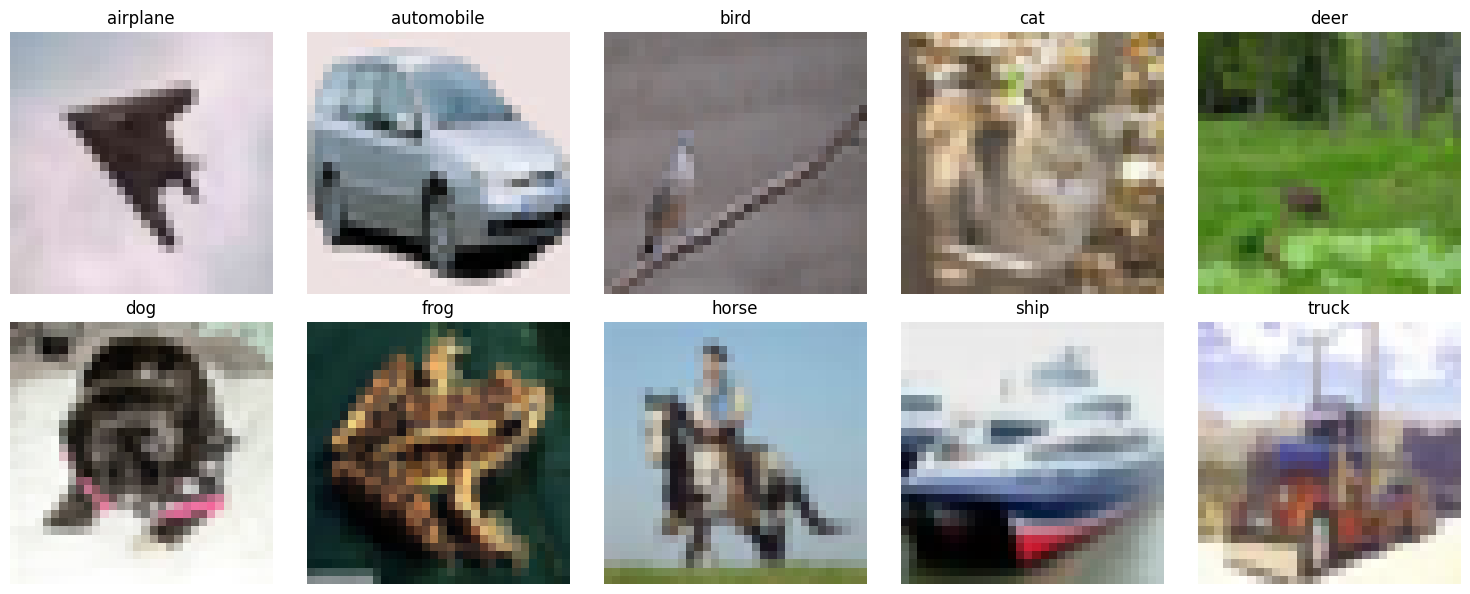

In [3]:
#define class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

#find one of each image and visualize
plt.figure(figsize=(15, 6))
for i in range(10):
    #get index of first image belonging to class i
    idx = np.where(y_train == i)[0][0]
    img = x_train[idx]

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(class_names[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

b) (30pts) demonstrate tuning of hyperparameters of the NN via grid search

In [4]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers

#first: preprocess the data:
# normalize pixel values to be between 0 and 1
x_train_scaled = x_train.astype('float32') / 255.0
x_val_scaled = x_val.astype('float32') / 255.0

#flatten the 32x32x3 arrays into vectors w/3072 features
x_train_flat = x_train_scaled.reshape(x_train_scaled.shape[0], -1)
x_val_flat = x_val_scaled.reshape(x_val_scaled.shape[0], -1)

# Convert class vectors to binary class matrices (One-Hot Encoding)
y_train_cat = tf.keras.utils.to_categorical(y_train, 10)
y_val_cat = tf.keras.utils.to_categorical(y_val, 10)

# 2. Define helper function to create model
def create_fc_model(hidden_units=256, learning_rate=0.001):
    model = models.Sequential([
        layers.Input(shape=(3072,)),
        layers.Dense(hidden_units, activation='relu'),
        layers.Dense(hidden_units // 2, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# 3. Define the Grid Search hyperparameters
param_grid = {
    'hidden_units': [256, 512],
    'learning_rate': [0.001, 0.0001]
}

best_accuracy = 0
best_params = {}
best_history = None
best_model = None

# Iterate over hyperparameter combinations
for units in param_grid['hidden_units']:
    for lr in param_grid['learning_rate']:
        print(f"Training model with hidden_units={units}, learning_rate={lr}...")

        model = create_fc_model(hidden_units=units, learning_rate=lr)

        # Training for a few epochs for demonstration/speed purposes
        history = model.fit(
            x_train_flat, y_train_cat,
            validation_data=(x_val_flat, y_val_cat),
            epochs=5,
            batch_size=128,
            verbose=1
        )

        val_acc = max(history.history['val_accuracy'])
        print(f"Validation accuracy achieved: {val_acc:.4f}\n")

        if val_acc > best_accuracy:
            best_accuracy = val_acc
            best_params = {'hidden_units': units, 'learning_rate': lr}
            best_history = history.history
            best_model = model

print("Grid Search completed!")
print(f"Best Parameters: {best_params}")
print(f"Best Validation Accuracy: {best_accuracy:.4f}")

Training model with hidden_units=256, learning_rate=0.001...
Epoch 1/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - accuracy: 0.2999 - loss: 1.9484 - val_accuracy: 0.3501 - val_loss: 1.8186
Epoch 2/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.3790 - loss: 1.7349 - val_accuracy: 0.3896 - val_loss: 1.7410
Epoch 3/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.4115 - loss: 1.6527 - val_accuracy: 0.4267 - val_loss: 1.6176
Epoch 4/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.4330 - loss: 1.5947 - val_accuracy: 0.4309 - val_loss: 1.5989
Epoch 5/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.4473 - loss: 1.5529 - val_accuracy: 0.4488 - val_loss: 1.5542
Validation accuracy achieved: 0.4488

Training model with hidden_units=256, learning_rate=0.0001...
Epoch 1/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.3141 - loss: 1.9241 - val_accuracy: 0.3338 - val_loss: 1.8382
Epoch 2/5
329/329 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.380

c) (5pts) calculate and plot the training and validation losses of the tuned network.

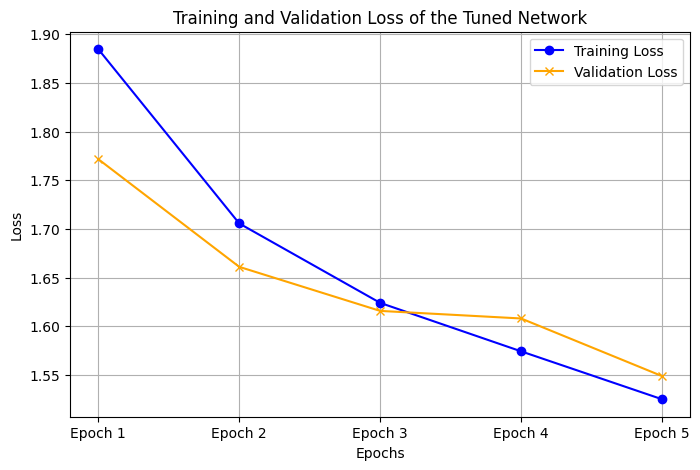

In [5]:
# Plot training and validation losses
plt.figure(figsize=(8, 5))
plt.plot(best_history['loss'], label='Training Loss', color='blue', marker='o')
plt.plot(best_history['val_loss'], label='Validation Loss', color='orange', marker='x')

plt.title('Training and Validation Loss of the Tuned Network')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.xticks(range(len(best_history['loss'])), [f"Epoch {i+1}" for i in range(len(best_history['loss']))])
plt.show()

d) (5pts) calculate and plot the training and validation accuracies of the tuned network.

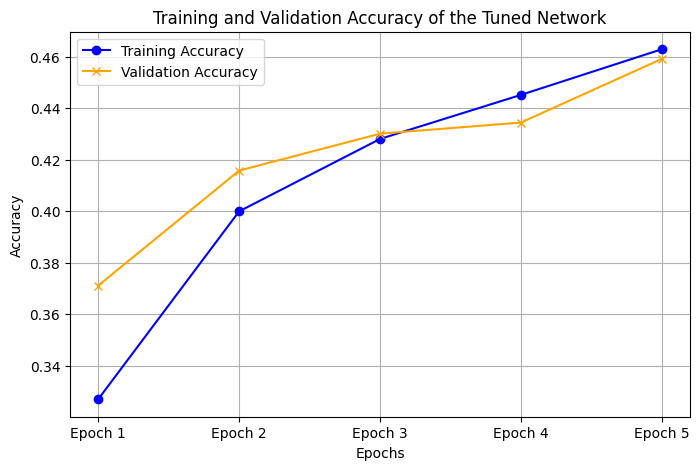

In [6]:
# Plot training and validation accuracies
plt.figure(figsize=(8, 5))
plt.plot(best_history['accuracy'], label='Training Accuracy', color='blue', marker='o')
plt.plot(best_history['val_accuracy'], label='Validation Accuracy', color='orange', marker='x')

plt.title('Training and Validation Accuracy of the Tuned Network')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.xticks(range(len(best_history['accuracy'])), [f"Epoch {i+1}" for i in range(len(best_history['accuracy']))])
plt.show()

2. Obtain the NASA airfoil self-noise dataset from UCI machine learning dataset repository. The dataset describes different sice NACA 0012 airfoiles at various wind tunnel speeds and angles of attack. The span of the airfoil and the observer position were the same in all the experiments. The following attributes were measured:

i. Frequency, in Hz
ii. Angle of attack, in degrees
iii. Chord length, in meters
iv. Free-stream velocity, in m/s
v. Suction Side displacement thickness, in meters

the only measured output was:

i. Scaled sound pressure level, in decibels

In [8]:
import pandas as pd

# URL of the dataset from UCI Machine Learning Repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00291/airfoil_self_noise.dat"

# Attribute names as described in the prompt
column_names = [
    "Frequency",
    "Angle_of_attack",
    "Chord_length",
    "Free_stream_velocity",
    "Suction_side_displacement",
    "Scaled_sound_pressure"
]

# Load the tab-separated dataset
df = pd.read_csv(url, sep='\t', names=column_names)

# Display basic information
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

Dataset Shape: (1503, 6)

First 5 rows:
   Frequency  Angle_of_attack  Chord_length  Free_stream_velocity  \
0        800              0.0        0.3048                  71.3   
1       1000              0.0        0.3048                  71.3   
2       1250              0.0        0.3048                  71.3   
3       1600              0.0        0.3048                  71.3   
4       2000              0.0        0.3048                  71.3   

   Suction_side_displacement  Scaled_sound_pressure  
0                   0.002663                126.201  
1                   0.002663                125.201  
2                   0.002663                125.951  
3                   0.002663                127.591  
4                   0.002663                127.461  


a. (10pts) Visualize the dataset.

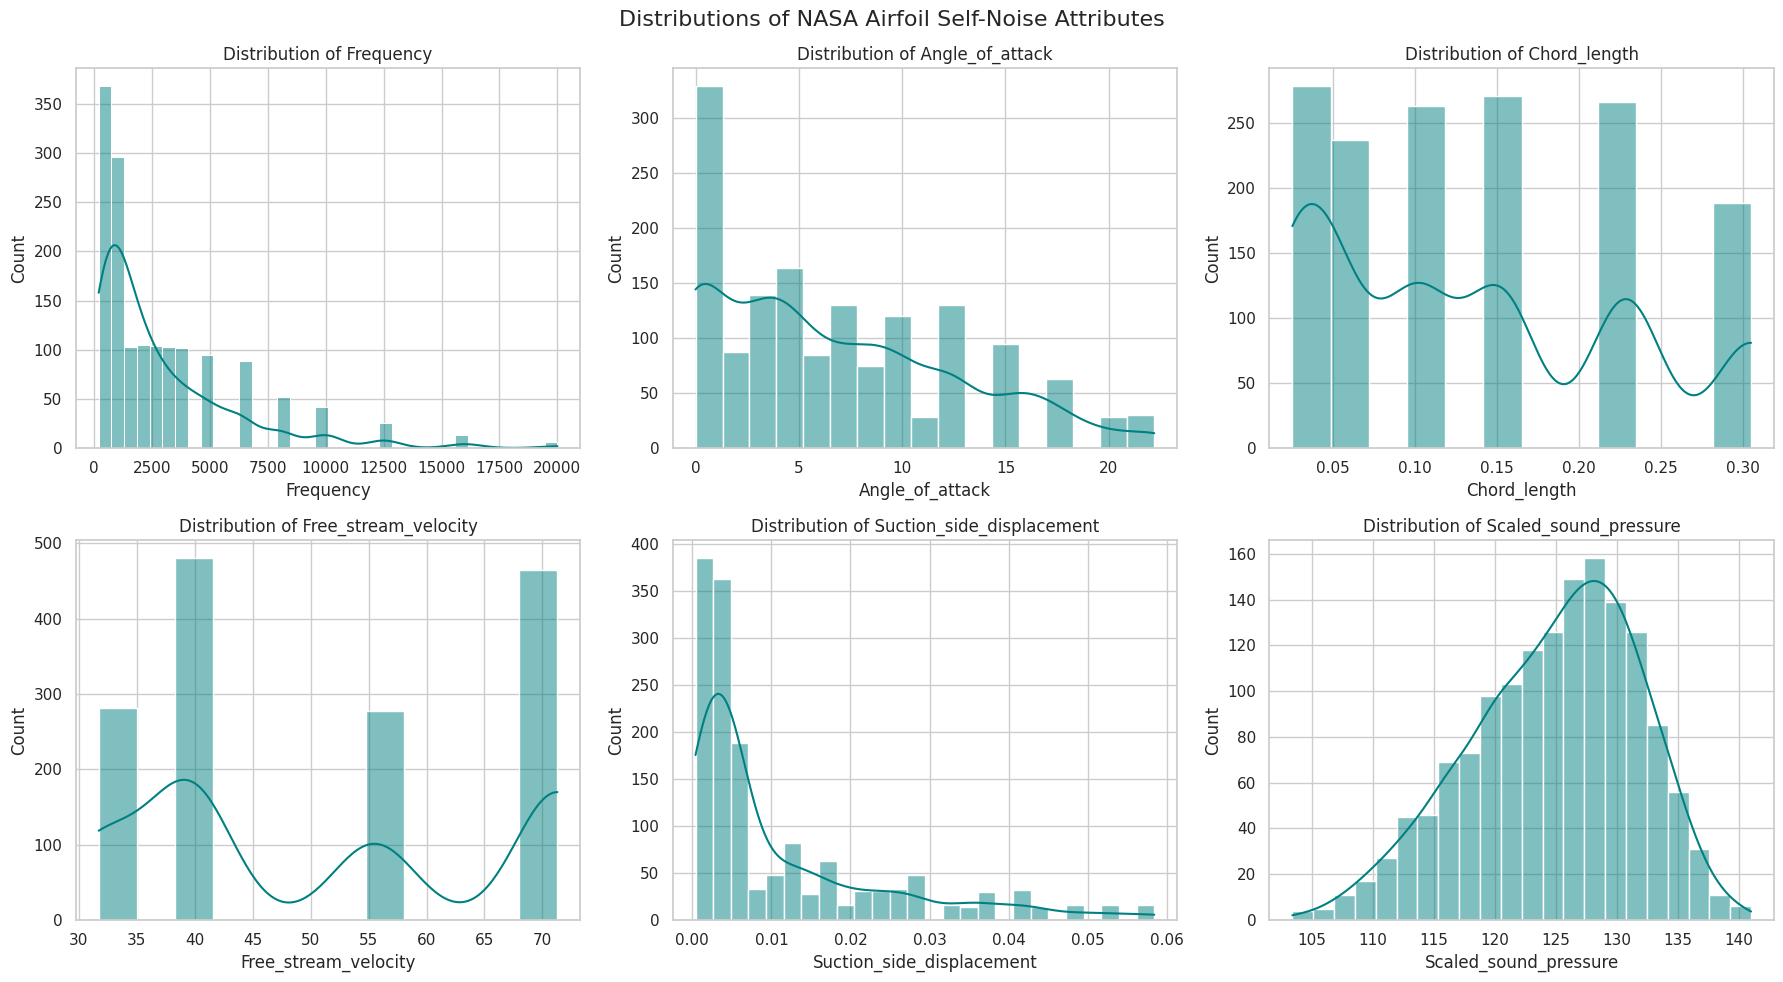

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for plotting
sns.set_theme(style="whitegrid")

# Create a 2x3 grid of subplots to visualize all 6 columns
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Distributions of NASA Airfoil Self-Noise Attributes", fontsize=16)

for i, col in enumerate(df.columns):
    ax = axes[i // 3, i % 3]
    sns.histplot(df[col], kde=True, ax=ax, color='teal')
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

b. (30pts) Construct a fully connected NN model for estimating scaled sound pressure level, in decibels, from the attributes by choosing 70%-30% split.

In [11]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras import models, layers

# 1. Separate features and target label
X = df.drop(columns=["Scaled_sound_pressure"]).values
y = df["Scaled_sound_pressure"].values

# 2. Perform 70%-30% train-validation split
X_train, X_val, y_train_reg, y_val_reg = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# 3. Standardize the features for efficient neural network training
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# 4. Construct the fully connected Neural Network for regression
reg_model = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1)  # Single output node for regression
])

# Compile the model with Mean Squared Error (MSE) loss
reg_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# 5. Train the model
print("Training the fully connected regression model...")
history_reg = reg_model.fit(
    X_train_scaled, y_train_reg,
    validation_data=(X_val_scaled, y_val_reg),
    epochs=150,
    batch_size=16,
    verbose=0
)

print("\nModel training completed!")

Training the fully connected regression model...

Model training completed!


c. (10pts) Calculate coefficient of determination.

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Validation R^2 Score (Coefficient of Determination): 0.7829
